# Dengue Severity Prediction — Leakage-Safe Machine Learning

This corrected notebook uses **exactly four models**:

1. Random Forest
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. AdaBoost

For **each model separately**, the notebook produces:
- Classification report
- Confusion matrix
- Multiclass ROC curves
- Training vs. validation accuracy curve
- Training vs. validation loss curve

### Leakage prevention
- `Severity` is taken directly from the dataset as the target.
- No `if/else` rule is used to create Severity.
- Train/test split occurs before fitting preprocessing.
- Imputation, encoding and scaling are fitted only on training data.
- SMOTE is applied only inside the training pipeline.
- Hyperparameter tuning, where used, is performed only on the training set.


In [1]:
# ============================================================
# 1. Install packages if needed
# ============================================================
# Google Colab users can uncomment this if necessary:
# !pip -q install imbalanced-learn openpyxl

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.model_selection import train_test_split, StratifiedKFold, learning_curve
from sklearn.pipeline import Pipeline as SkPipeline

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score,
    log_loss,
    precision_score,
    recall_score,
    f1_score
)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")


Libraries imported successfully.


In [4]:
import os
# ============================================================
# 2. Load Dataset
# ============================================================
candidate_paths = [
    "/content/Final_dataset (1).xlsx",
    "/content/Final_dataset.xlsx",
    "/mnt/data/Final_dataset (1).xlsx"
]

DATA_PATH = next((p for p in candidate_paths if os.path.exists(p)), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Please upload Final_dataset (1).xlsx "
        "to Colab or update DATA_PATH."
    )

df = pd.read_excel(DATA_PATH)

print("Dataset:", DATA_PATH)
print("Shape:", df.shape)

display(df.head())

Dataset: /content/Final_dataset (1).xlsx
Shape: (1555, 10)


,Age,Sex,Hb,HCT,TC,PC,NS1,IgG,IgM,Severity
0,70.0,Female,12.96,39.08,4.22,96.55,Pos,Neg,Neg,Severe
1,27.0,Male,16.11,48.02,12.67,249.86,Neg,Neg,Neg,Severe
2,20.0,Female,14.11,42.19,2.42,164.57,Pos,Neg,Neg,Moderate
3,25.0,Female,10.61,32.28,2.90,167.98,Neg,Neg,Neg,Severe
4,9.0,Male,9.24,28.10,10.99,257.68,Neg,Neg,Neg,Severe


In [6]:
# ============================================================
# 3. Basic Dataset Inspection
# ============================================================
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)


Columns:
['Age', 'Sex', 'Hb', 'HCT', 'TC', 'PC', 'NS1', 'IgG', 'IgM', 'Severity']

Data types:


,dtype
Age,float64
Sex,object
Hb,float64
HCT,float64
TC,float64
PC,float64
NS1,object
IgG,object
IgM,object
Severity,object



Missing values:


,missing_count
Age,0
Sex,26
Hb,0
HCT,0
TC,0
PC,0
NS1,0
IgG,0
IgM,0
Severity,0



Duplicate rows: 0

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1555.0,NaN,NaN,NaN,26.557685,12.930372,3.0,19.0,25.0,32.0,70.0
Sex,1529,2,Male,884,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hb,1555.0,NaN,NaN,NaN,12.950836,1.69936,8.17,11.92,12.93,14.11,17.37
HCT,1555.0,NaN,NaN,NaN,38.984309,15.032954,2.84,35.795,38.94,42.465,440.51
TC,1555.0,NaN,NaN,NaN,6.662791,6.946565,1.67,3.99,5.74,6.64,82.36
PC,1555.0,NaN,NaN,NaN,195.441132,77.897273,32.37,140.02,204.42,229.985,441.46
NS1,1555,2,Pos,796,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IgG,1555,2,Neg,1388,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IgM,1555,2,Neg,1547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Severity,1555,3,Severe,544,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Count,Percentage
Severity,,
Severe,544,34.98
Moderate,533,34.28
Mild,478,30.74


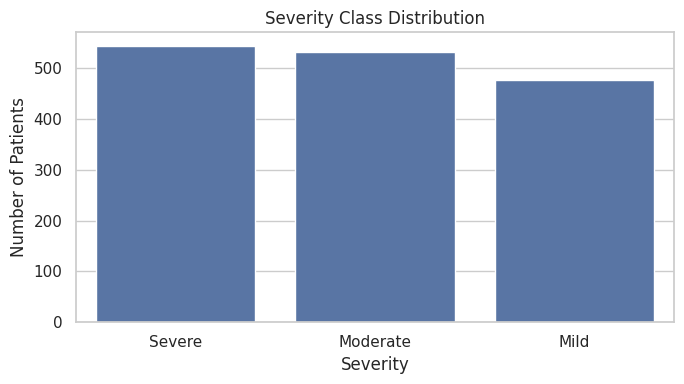

In [7]:
# ============================================================
# 4. Severity Distribution
# ============================================================
TARGET = "Severity"

if TARGET not in df.columns:
    raise ValueError(f"'{TARGET}' column was not found.")

df = df.dropna(subset=[TARGET]).copy()

severity_table = pd.DataFrame({
    "Count": df[TARGET].value_counts(),
    "Percentage": df[TARGET].value_counts(normalize=True).mul(100).round(2)
})

display(severity_table)

plt.figure(figsize=(7, 4))
sns.countplot(
    data=df,
    x=TARGET,
    order=df[TARGET].value_counts().index
)
plt.title("Severity Class Distribution")
plt.xlabel("Severity")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()


In [8]:
# ============================================================
# 5. Define X and y — NO IF/ELSE SEVERITY RULE
# ============================================================
# Severity is the observed target from the dataset.
# It is NEVER reconstructed from PC/HCT/TC or any other feature.

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].astype(str).copy()

print("Target:", TARGET)
print("Classes:", sorted(y.unique()))
print("Number of observations:", len(y))
print("Features:")
print(X.columns.tolist())


Target: Severity
Classes: ['Mild', 'Moderate', 'Severe']
Number of observations: 1555
Features:
['Age', 'Sex', 'Hb', 'HCT', 'TC', 'PC', 'NS1', 'IgG', 'IgM']


In [9]:
# ============================================================
# 6. Train/Test Split
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

print("\nTraining distribution:")
display(y_train.value_counts().to_frame("count"))

print("\nTesting distribution:")
display(y_test.value_counts().to_frame("count"))


Training: (1244, 9)
Testing : (311, 9)

Training distribution:


,count
Severity,
Severe,435
Moderate,426
Mild,383



Testing distribution:


,count
Severity,
Severe,109
Moderate,107
Mild,95


In [10]:
# ============================================================
# 7. Preprocessing
# ============================================================
numeric_features = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

numeric_pipeline = SkPipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = SkPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Leakage-safe preprocessing created.")


Numeric features: ['Age', 'Hb', 'HCT', 'TC', 'PC']
Categorical features: ['Sex', 'NS1', 'IgG', 'IgM']
Leakage-safe preprocessing created.


In [11]:
# ============================================================
# 8. Define Four Models
# ============================================================

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    ),

    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=2,
            min_samples_leaf=10,
            random_state=RANDOM_STATE
        ),
        n_estimators=200,
        learning_rate=0.1,
        random_state=RANDOM_STATE
    )
}

print("Models:")
for name in models:
    print("-", name)


Models:
- Random Forest
- Decision Tree
- KNN
- AdaBoost


In [12]:
# ============================================================
# 9. Create Leakage-Safe Pipelines
# ============================================================
# SMOTE is inside the pipeline.
# Therefore it is applied only to training data during fitting/CV.
#
# KNN requires scaling; tree models do not.

pipelines = {}

for name, model in models.items():

    steps = [
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE))
    ]

    if name == "KNN":
        steps.append(("scaler", StandardScaler()))

    steps.append(("model", model))

    pipelines[name] = Pipeline(steps)

print("Four leakage-safe pipelines created.")


Four leakage-safe pipelines created.


In [13]:
# ============================================================
# 10. Fit All Four Models
# ============================================================
fitted_models = {}

for name, pipeline in pipelines.items():
    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

print("\nAll four models trained.")


Training Random Forest...
Training Decision Tree...
Training KNN...
Training AdaBoost...

All four models trained.


In [14]:
# ============================================================
# 11. Classification Reports + Metrics
# ============================================================
classes = np.unique(y_train)

results = []
predictions = {}
probabilities = {}

for name, model in fitted_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    predictions[name] = y_pred
    probabilities[name] = y_prob

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob,
        multi_class="ovr",
        average="weighted",
        labels=model.classes_
    )

    loss = log_loss(
        y_test,
        y_prob,
        labels=model.classes_
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "ROC-AUC": auc_score,
        "Log Loss": loss
    })

    print("\n" + "=" * 80)
    print(f"{name} — CLASSIFICATION REPORT")
    print("=" * 80)
    print(classification_report(
        y_test,
        y_pred,
        digits=4
    ))

results_df = pd.DataFrame(results).sort_values(
    "F1-score",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Log Loss": "{:.4f}"
    })
)



Random Forest — CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Mild     0.9794    1.0000    0.9896        95
    Moderate     0.9906    0.9813    0.9859       107
      Severe     1.0000    0.9908    0.9954       109

    accuracy                         0.9904       311
   macro avg     0.9900    0.9907    0.9903       311
weighted avg     0.9905    0.9904    0.9904       311


Decision Tree — CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Mild     0.9588    0.9789    0.9688        95
    Moderate     0.9623    0.9533    0.9577       107
      Severe     0.9907    0.9817    0.9862       109

    accuracy                         0.9711       311
   macro avg     0.9706    0.9713    0.9709       311
weighted avg     0.9712    0.9711    0.9711       311


KNN — CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Mild     0.9684    0.9684    0.9684        95
    Moderate     0.945

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Log Loss
0,Random Forest,0.9904,0.9905,0.9904,0.9904,0.9999,0.0963
1,AdaBoost,0.9775,0.9779,0.9775,0.9776,0.9989,0.9091
2,Decision Tree,0.9711,0.9712,0.9711,0.9711,0.9895,0.4954
3,KNN,0.9678,0.9681,0.9678,0.9679,0.9899,0.4407


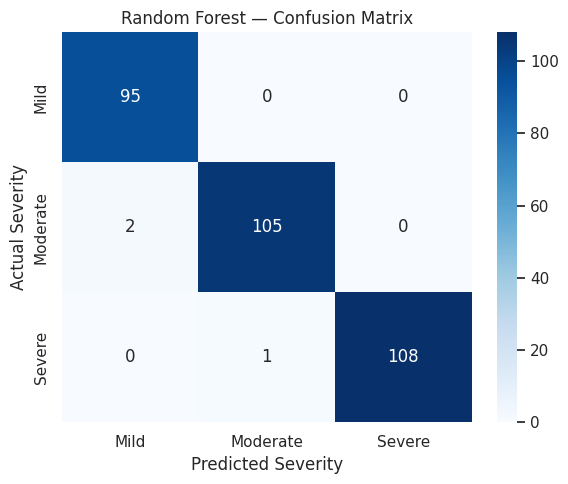

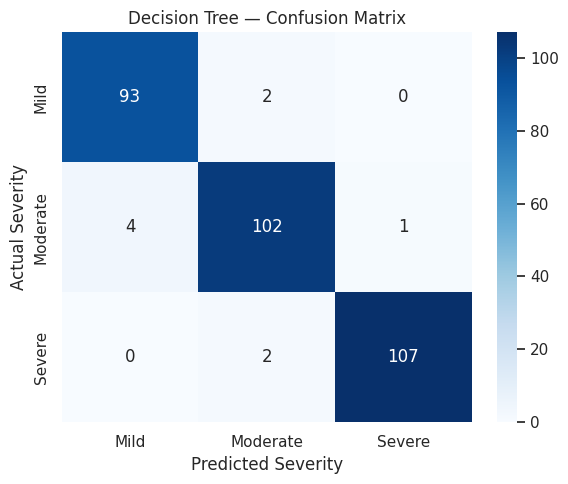

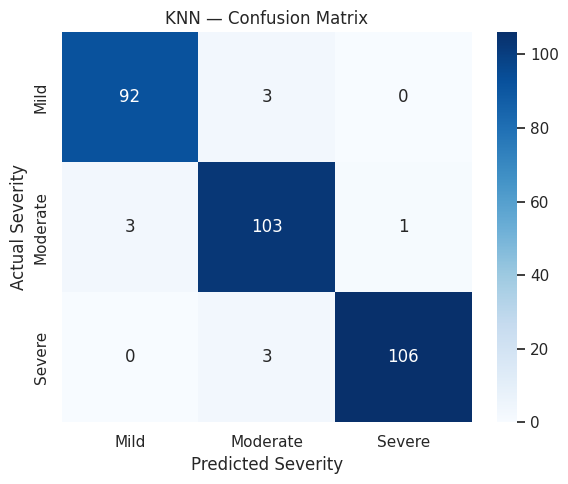

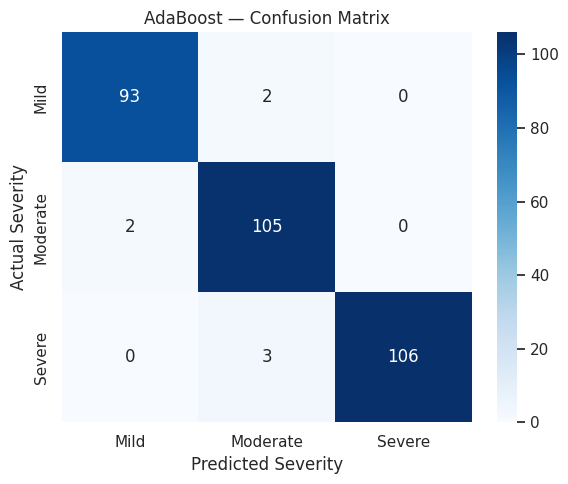

In [15]:
# ============================================================
# 12. CONFUSION MATRICES — SEPARATELY FOR ALL MODELS
# ============================================================

for name in fitted_models:

    y_pred = predictions[name]

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=fitted_models[name].classes_
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=fitted_models[name].classes_,
        yticklabels=fitted_models[name].classes_
    )

    plt.title(f"{name} — Confusion Matrix")
    plt.xlabel("Predicted Severity")
    plt.ylabel("Actual Severity")
    plt.tight_layout()
    plt.show()


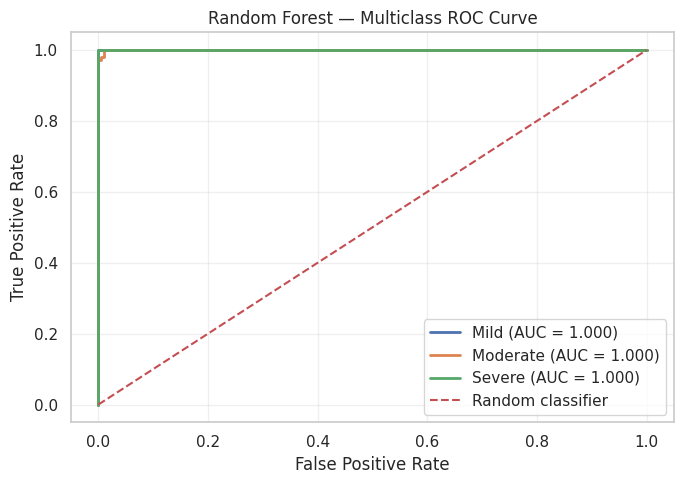

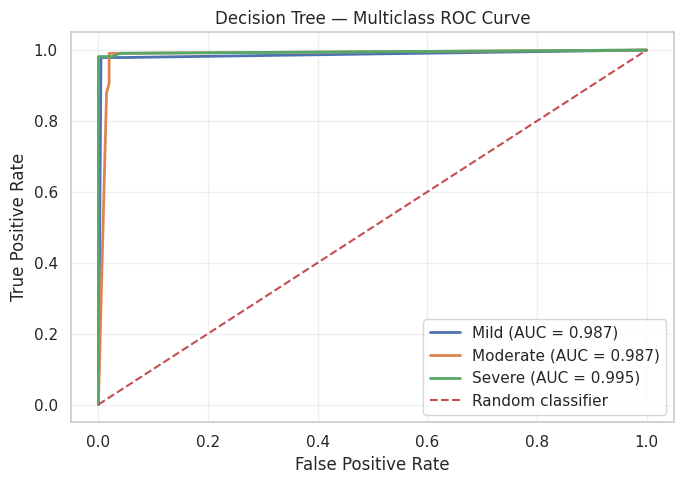

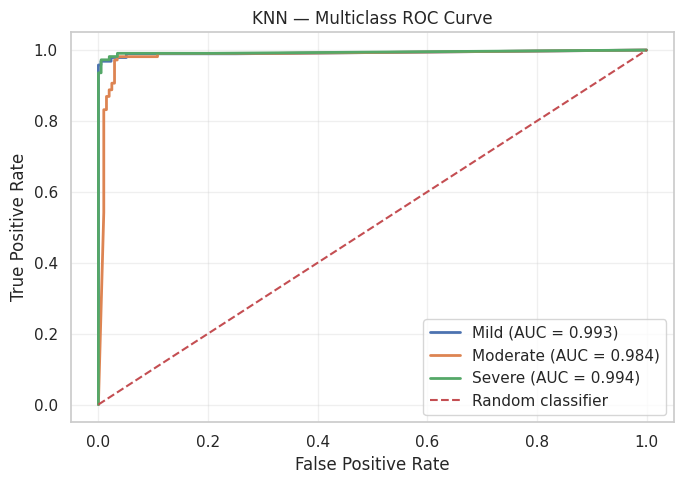

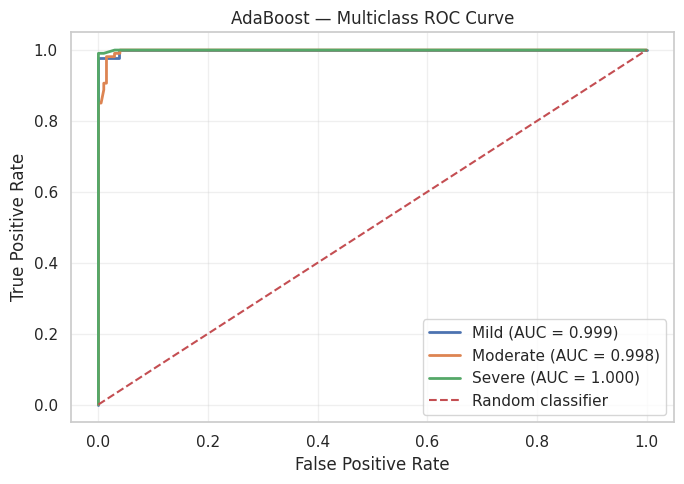

In [16]:
# ============================================================
# 13. ROC CURVES — SEPARATELY FOR ALL MODELS
# ============================================================

for name, model in fitted_models.items():

    y_prob = probabilities[name]
    model_classes = model.classes_

    y_test_binary = label_binarize(
        y_test,
        classes=model_classes
    )

    plt.figure(figsize=(7, 5))

    for i, cls in enumerate(model_classes):

        fpr, tpr, _ = roc_curve(
            y_test_binary[:, i],
            y_prob[:, i]
        )

        class_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{cls} (AUC = {class_auc:.3f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{name} — Multiclass ROC Curve")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


## Training vs. Validation Curves

For each model, the following two plots are generated independently:

- **Training vs. Validation Accuracy**
- **Training vs. Validation Loss**

The curves are based on stratified cross-validation of the complete leakage-safe pipeline. Thus preprocessing and SMOTE are recalculated inside each training fold rather than using information from the validation fold.


Calculating accuracy curve for Random Forest...


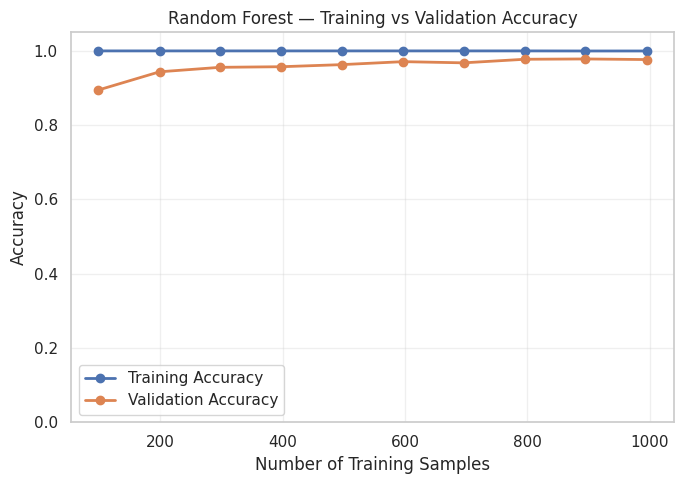

Calculating accuracy curve for Decision Tree...


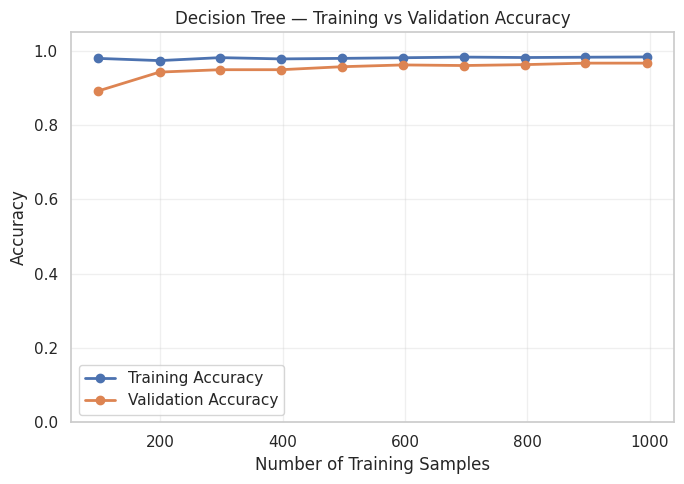

Calculating accuracy curve for KNN...


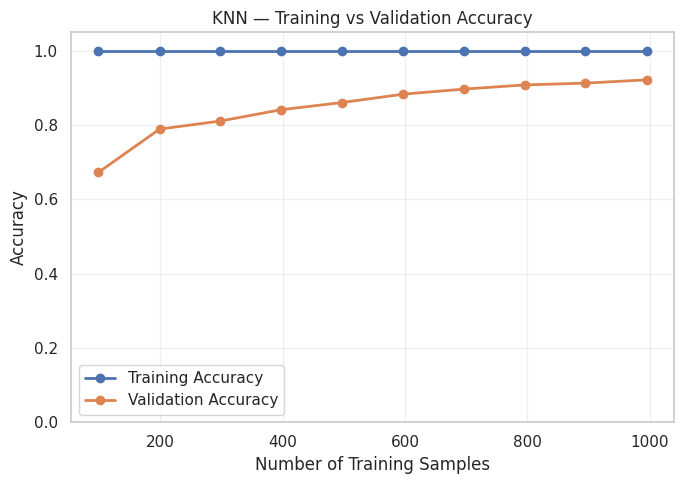

Calculating accuracy curve for AdaBoost...


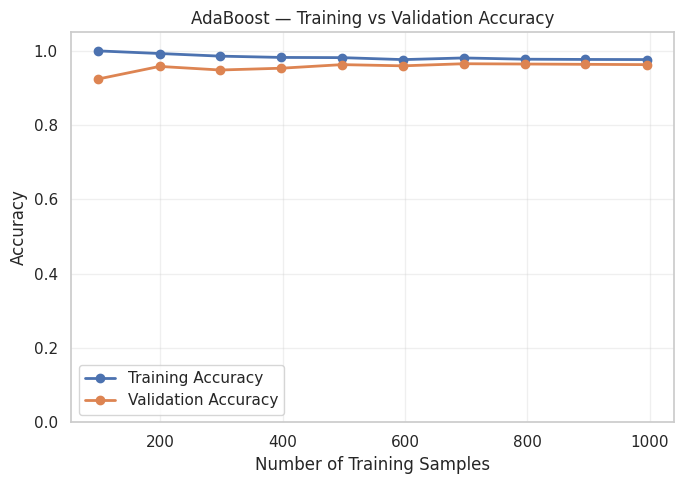

In [17]:
# ============================================================
# 14. TRAINING vs VALIDATION ACCURACY CURVES
#     SEPARATELY FOR ALL MODELS
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

learning_curve_data = {}

for name, model in fitted_models.items():

    print(f"Calculating accuracy curve for {name}...")

    train_sizes, train_scores, validation_scores = learning_curve(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        train_sizes=np.linspace(0.1, 1.0, 10),
        n_jobs=-1
    )

    train_mean = train_scores.mean(axis=1)
    validation_mean = validation_scores.mean(axis=1)

    learning_curve_data[name] = {
        "train_sizes": train_sizes,
        "train_accuracy": train_mean,
        "validation_accuracy": validation_mean
    }

    plt.figure(figsize=(7, 5))

    plt.plot(
        train_sizes,
        train_mean,
        marker="o",
        linewidth=2,
        label="Training Accuracy"
    )

    plt.plot(
        train_sizes,
        validation_mean,
        marker="o",
        linewidth=2,
        label="Validation Accuracy"
    )

    plt.title(f"{name} — Training vs Validation Accuracy")
    plt.xlabel("Number of Training Samples")
    plt.ylabel("Accuracy")
    plt.ylim(0, 1.05)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


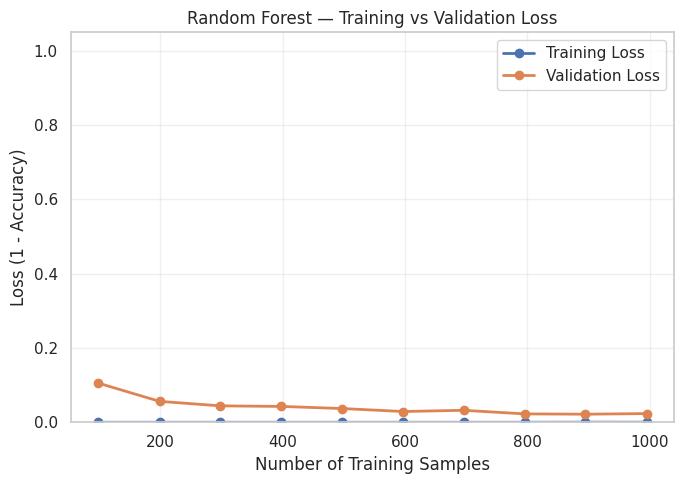

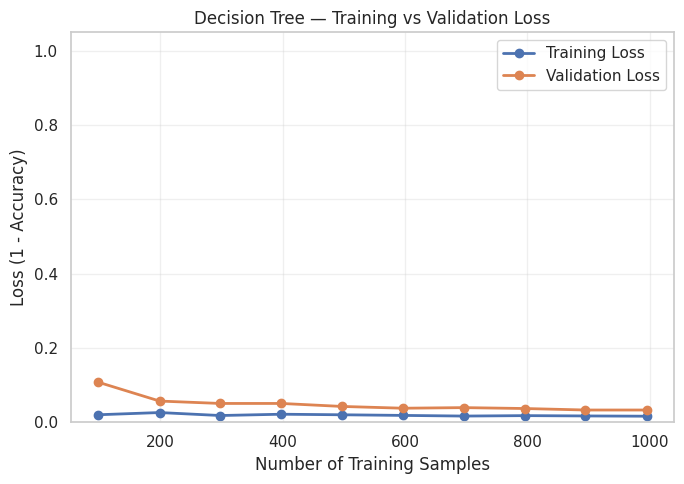

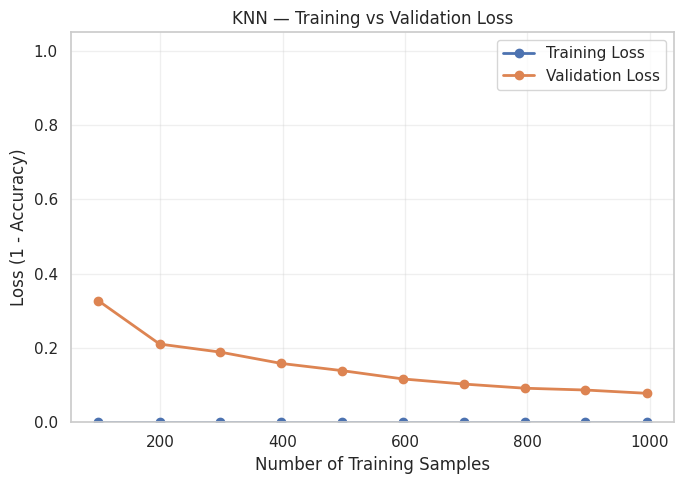

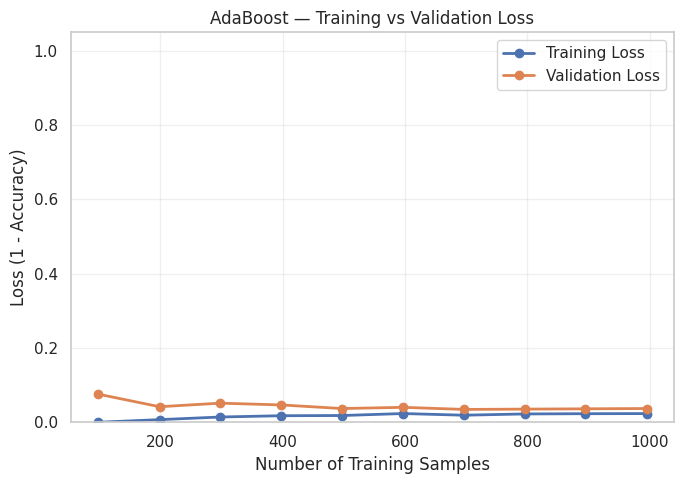

In [18]:
# ============================================================
# 15. TRAINING vs VALIDATION LOSS CURVES
#     SEPARATELY FOR ALL MODELS
# ============================================================
# Since learning_curve above uses accuracy, classification loss
# is represented consistently as:
#
#       Loss = 1 - Accuracy
#
# This provides a direct training-vs-validation loss curve for
# every model using the same evaluation framework.

for name, data in learning_curve_data.items():

    train_loss = 1 - data["train_accuracy"]
    validation_loss = 1 - data["validation_accuracy"]

    plt.figure(figsize=(7, 5))

    plt.plot(
        data["train_sizes"],
        train_loss,
        marker="o",
        linewidth=2,
        label="Training Loss"
    )

    plt.plot(
        data["train_sizes"],
        validation_loss,
        marker="o",
        linewidth=2,
        label="Validation Loss"
    )

    plt.title(f"{name} — Training vs Validation Loss")
    plt.xlabel("Number of Training Samples")
    plt.ylabel("Loss (1 - Accuracy)")
    plt.ylim(0, 1.05)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


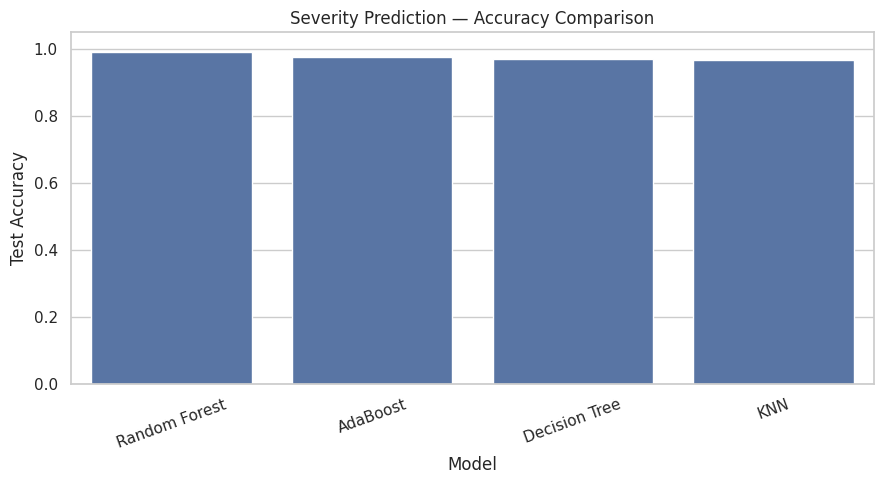

In [19]:
# ============================================================
# 16. MODEL COMPARISON — ACCURACY
# ============================================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.ylim(0, 1.05)
plt.title("Severity Prediction — Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


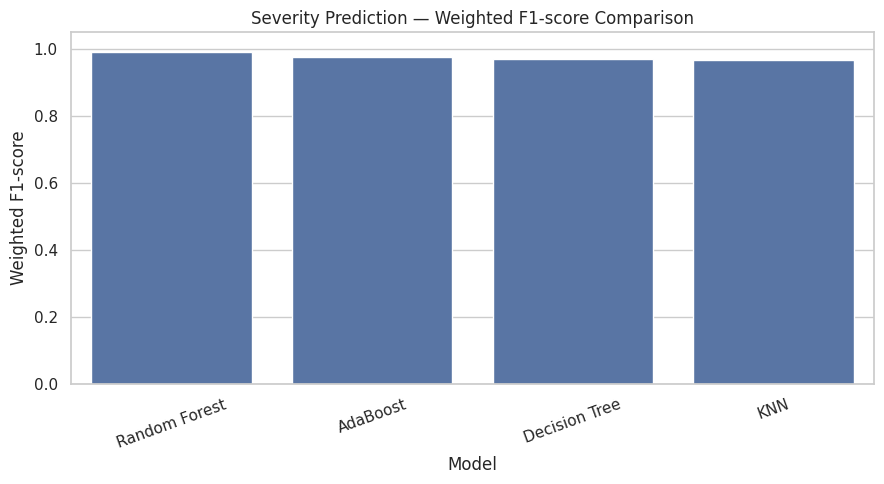

In [21]:
# ============================================================
# 17. MODEL COMPARISON — F1 SCORE
# ============================================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1-score"
)

plt.ylim(0, 1.05)
plt.title("Severity Prediction — Weighted F1-score Comparison")
plt.xlabel("Model")
plt.ylabel("Weighted F1-score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [20]:
# ============================================================
# 18. Save Classification Reports and Results
# ============================================================

results_path = "/content/dengue_severity_four_model_results.csv"
reports_path = "/content/dengue_severity_four_model_classification_reports.txt"

results_df.to_csv(
    results_path,
    index=False
)

with open(reports_path, "w", encoding="utf-8") as f:

    for name in fitted_models:

        f.write("\n" + "=" * 80 + "\n")
        f.write(f"{name} — CLASSIFICATION REPORT\n")
        f.write("=" * 80 + "\n")

        f.write(
            classification_report(
                y_test,
                predictions[name],
                digits=4
            )
        )

print("Results saved:")
print(results_path)
print(reports_path)


Results saved:
/content/dengue_severity_four_model_results.csv
/content/dengue_severity_four_model_classification_reports.txt


## Final Checklist

The notebook now contains **only the four requested models**:

| Model | Classification Report | Confusion Matrix | ROC Curve | Train/Validation Accuracy | Train/Validation Loss |
|---|---|---|---|---|---|
| Random Forest | ✓ | ✓ | ✓ | ✓ | ✓ |
| Decision Tree | ✓ | ✓ | ✓ | ✓ | ✓ |
| KNN | ✓ | ✓ | ✓ | ✓ | ✓ |
| AdaBoost | ✓ | ✓ | ✓ | ✓ | ✓ |

All four models use the same leakage-safe preprocessing and SMOTE framework.

**Important:** If the original `Severity` labels were constructed using PC, HCT, TC or other predictors, this should be disclosed as a potential label-proxy issue in the research paper. The notebook itself does not reconstruct Severity with rules or use the target to preprocess the data.
